# Differential drag: propellant-free along-track control

Every relative-motion tool built so far assumes two-body gravity, at most with J2 added, and every change of relative orbit so far has come from an impulsive burn. Atmospheric drag is the perturbation missing from that picture, and it brings something genuinely useful along with it: two spacecraft sharing almost the same orbit but differing in ballistic coefficient decay at different rates, drifting apart along-track for free. This is differential drag, a real technique used for propellant-free formation keeping and phasing in low Earth orbit, and this notebook builds and validates the perturbation that makes it work.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import MU_EARTH, R_EARTH, OMEGA_EARTH
from ios_mission_planner.dynamics.orbital.drag import two_body_drag_dynamics_symbolic
from ios_mission_planner.dynamics.relative.lvlh import inertial_to_lvlh
from ios_mission_planner.propagation.heyoka_propagator import propagate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## A single orbit's decay

`two_body_drag_dynamics_symbolic` adds `drag_acceleration_symbolic` to plain two-body motion: drag opposes the velocity relative to the corotating atmosphere, scaled by density (an exponential model, `exponential_atmosphere_density`, falling off with altitude from one reference point) and by the ballistic coefficient `bc = Cd*A/m`. The atmosphere parameters below are illustrative, representative of the right order of magnitude for a ~450 km orbit, not a precise forecast; real density varies with solar activity, local time, and latitude well beyond what one exponential band captures, and this model is not meant to replace a proper atmosphere model for anything beyond sizing the effect.

In [2]:
alt_chief = 450.0
a0 = R_EARTH + alt_chief
v0 = np.sqrt(MU_EARTH / a0)
state0 = np.array([a0, 0.0, 0.0, 0.0, v0, 0.0])
period = 2 * np.pi * np.sqrt(a0**3 / MU_EARTH)

rho0, r0, scale_height = 1.0e-12, a0, 60.0  # illustrative 450 km band
bc_reference = 0.02  # Cd*A/m, m^2/kg

t_eval = np.linspace(0.0, 20 * period, 3000)
sol = propagate(
    two_body_drag_dynamics_symbolic(), state0, t_eval,
    pars=[MU_EARTH, bc_reference, rho0, r0, scale_height, OMEGA_EARTH],
).y

r = np.linalg.norm(sol[:3, :], axis=0)
v = np.linalg.norm(sol[3:6, :], axis=0)
a_series = -MU_EARTH / (2 * (0.5 * v**2 - MU_EARTH / r))

print(f"semi-major axis: {a_series[0]:.3f} km -> {a_series[-1]:.3f} km over 20 orbits "
      f"({(a_series[-1] - a_series[0]) * 1e3:.1f} m)")

semi-major axis: 6828.137 km -> 6828.035 km over 20 orbits (-102.5 m)


## Two identical orbits, two different ballistic coefficients

Starting a chief and a deputy on the exact same orbit, but giving the deputy a higher ballistic coefficient (more drag for the same density and speed, as a larger or less streamlined cross-section would give), is enough on its own to pull them apart along-track, with no maneuver anywhere.

along-track separation after 10 orbits: 2415.8 m, after 20 orbits: 9662.2 m


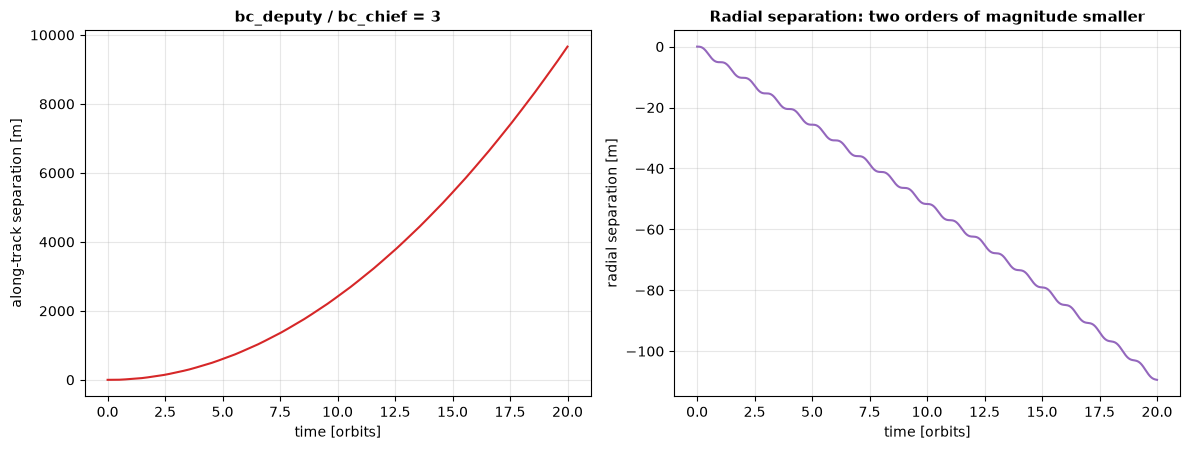

In [3]:
bc_chief, bc_deputy = 0.01, 0.03

sol_c = propagate(
    two_body_drag_dynamics_symbolic(), state0, t_eval,
    pars=[MU_EARTH, bc_chief, rho0, r0, scale_height, OMEGA_EARTH],
).y
sol_d = propagate(
    two_body_drag_dynamics_symbolic(), state0, t_eval,
    pars=[MU_EARTH, bc_deputy, rho0, r0, scale_height, OMEGA_EARTH],
).y

rel = np.array([inertial_to_lvlh(sol_c[:, i], sol_d[:, i]) for i in range(len(t_eval))]).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

axes[0].plot(t_eval / period, rel[1, :] * 1e3, color=COL_NUM)
axes[0].set_xlabel("time [orbits]")
axes[0].set_ylabel("along-track separation [m]")
axes[0].set_title(f"bc_deputy / bc_chief = {bc_deputy / bc_chief:.0f}")

axes[1].plot(t_eval / period, rel[0, :] * 1e3, color=COL_ZONE)
axes[1].set_xlabel("time [orbits]")
axes[1].set_ylabel("radial separation [m]")
axes[1].set_title("Radial separation: two orders of magnitude smaller")

fig.tight_layout()

print(f"along-track separation after 10 orbits: {rel[1, len(t_eval)//2]*1e3:.1f} m, "
      f"after 20 orbits: {rel[1, -1]*1e3:.1f} m")

The deputy, decaying faster, drops to a slightly lower, slightly faster orbit and pulls steadily ahead along-track, exactly the $\delta a$-driven secular drift that the relative orbit elements describe: a difference in semi-major axis always turns into an along-track drift, whether it comes from a thruster or, as here, from nothing but a difference in cross-section. The radial separation, by contrast, stays two orders of magnitude smaller throughout, since both orbits remain close to circular and nearly coplanar; differential drag is primarily an along-track effect, not a way to open up radial or cross-track separation on anything like the same scale.

## How the drift rate scales with the ballistic coefficient difference

Since the only thing different between the chief and the deputy above is `bc`, sweeping the ratio shows how directly the along-track drift rate scales with how different the two objects' drag actually is.

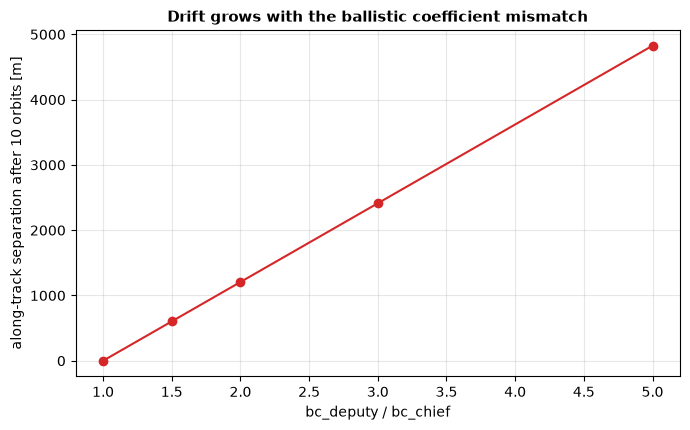

In [4]:
bc_ratios = np.array([1.0, 1.5, 2.0, 3.0, 5.0])
drift_at_10_orbits = []

idx_10 = np.argmin(np.abs(t_eval - 10 * period))
for ratio in bc_ratios:
    sol_d_i = propagate(
        two_body_drag_dynamics_symbolic(), state0, t_eval,
        pars=[MU_EARTH, bc_chief * ratio, rho0, r0, scale_height, OMEGA_EARTH],
    ).y
    rel_i = inertial_to_lvlh(sol_c[:, idx_10], sol_d_i[:, idx_10])
    drift_at_10_orbits.append(rel_i[1] * 1e3)

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(bc_ratios, drift_at_10_orbits, "o-", color=COL_NUM)
ax.set_xlabel("bc_deputy / bc_chief")
ax.set_ylabel("along-track separation after 10 orbits [m]")
ax.set_title("Drift grows with the ballistic coefficient mismatch")
fig.tight_layout()

## Summary

`two_body_drag_dynamics_symbolic` and the combined `two_body_j2_drag_dynamics_symbolic` add an exponential-atmosphere drag perturbation to this project's dynamics, validated here on two fronts: a single orbit decays under drag in the expected direction and rough magnitude, and two spacecraft started on the identical orbit but with different ballistic coefficients drift apart along-track with no propellant spent anywhere, growing with the size of the ballistic coefficient mismatch. This is a real technique, used operationally for propellant-free formation keeping and phasing in low Earth orbit, usually by changing attitude to present a different cross-section rather than by carrying different hardware.

What this notebook does not build is control: both ballistic coefficients were held fixed throughout, so the two objects only ever drift apart, never converge to a target separation. A real differential-drag controller switches which object carries the higher drag over time, which needs nothing new physically, the same `bc` parameter used here, just varied on a schedule, but is a genuine control-design problem left open rather than solved by this notebook.